<a href="https://colab.research.google.com/github/dev-pa5an/windguard-offshore-wind-forecasting/blob/1-create-the-ml-model/Tahkoluoto_offshore_wind_farm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Tahkoluoto offshore wind farm**

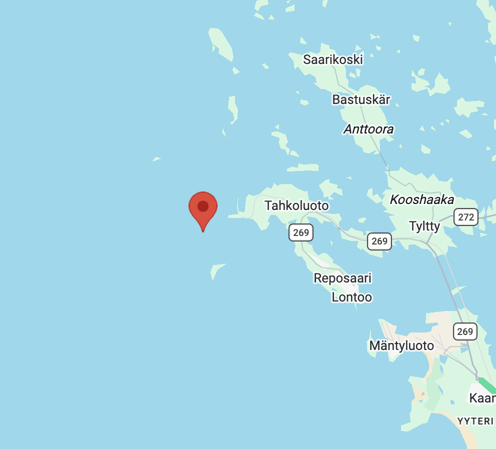

In [7]:
from PIL import Image

img = Image.open("Tahkoluoto offshore wind farm.png")
width, height = img.size
resized_img = img.resize((int(width * 0.5), int(height * 0.5)))
resized_img.save("resized_image.png")
resized_img

In [1]:
!pip install -q ecmwf-datastores-client pyyaml itables

In [2]:
import yaml
import os
from google.colab import userdata

# Get your API key from Colab Secrets
key = userdata.get('CDS_API_KEY')

# CDS API URL
url = "https://cds.climate.copernicus.eu/api"

# Create credentials dictionary
credentials = {
    "url": url,
    "key": key
}

# Create configuration file in home directory
home_dir = os.path.expanduser("~")
config_path = os.path.join(home_dir, ".ecmwfdatastoresrc")

with open(config_path, "w") as f:
    yaml.safe_dump(credentials, f)

print("Your connection details have been saved!")

Your connection details have been saved!


In [ ]:
from ecmwf.datastores import Client

client = Client()
client.check_authentication()

In [8]:
from ecmwf.datastores import Client

client = Client()

dataset = "reanalysis-era5-single-levels-timeseries"

request = {
    "variable": [
        "100m_u_component_of_wind",
        "100m_v_component_of_wind"
    ],

    "date": [
        "2015-01-01",
        "2024-12-31"
    ],

    # wind farm location
    "location": {
        "longitude": 21.358056,
        "latitude": 61.626111
    },

    "data_format": "netcdf"
}

target = "era5_north_sea_2015_2024.nc"

client.retrieve(
    dataset,
    request,
    target=target
)

print("Download completed!")

81f40c803125f32f9f66872687b723ab.zip:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Download completed!


In [12]:
import zipfile

zip_path = "/content/era5_north_sea_2015_2024.nc"
extract_dir = "/content/era5_extracted"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside archive:", zip_ref.namelist())
    zip_ref.extractall(extract_dir)

Files inside archive: ['reanalysis-era5-single-levels-timeseries-sfcsyxfo0nm.nc']


In [13]:
import xarray as xr

nc_file = os.path.join(
    extract_dir,
    "reanalysis-era5-single-levels-timeseries-sfcsyxfo0nm.nc"
)

ds_all = xr.open_dataset(nc_file)

print(ds_all)


<xarray.Dataset> Size: 1MB
Dimensions:     (valid_time: 87672)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 701kB 2015-01-01 ... 2024-12-31T2...
    latitude    float64 8B ...
    longitude   float64 8B ...
Data variables:
    u100        (valid_time) float32 351kB ...
    v100        (valid_time) float32 351kB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts


In [14]:
print(ds_all.data_vars)
print(ds_all.dims)

Data variables:
    u100     (valid_time) float32 351kB ...
    v100     (valid_time) float32 351kB ...
FrozenMappingWarningOnValuesAccess({'valid_time': 87672})


In [15]:
import numpy as np
import pandas as pd

wind_speed = np.sqrt(ds_all["u100"]**2 + ds_all["v100"]**2)

df = pd.DataFrame({
    "timestamp": ds_all["valid_time"].values,
    "u100": ds_all["u100"].values,
    "v100": ds_all["v100"].values,
    "wind_speed": wind_speed.values
})

df = df.sort_values("timestamp").reset_index(drop=True)

print(df.head())
print(df.shape)
print(df.isnull().sum())

            timestamp      u100      v100  wind_speed
0 2015-01-01 00:00:00  9.681625 -1.973022    9.880622
1 2015-01-01 01:00:00  8.863464 -2.097458    9.108256
2 2015-01-01 02:00:00  8.099396 -2.108521    8.369353
3 2015-01-01 03:00:00  7.593658 -1.090057    7.671498
4 2015-01-01 04:00:00  7.214920  0.584946    7.238594
(87672, 4)
timestamp     0
u100          0
v100          0
wind_speed    0
dtype: int64


In [16]:
print(df["wind_speed"].describe())

count    87672.000000
mean         7.811007
std          3.663448
min          0.029106
25%          5.085877
50%          7.491427
75%         10.164741
max         24.208242
Name: wind_speed, dtype: float64


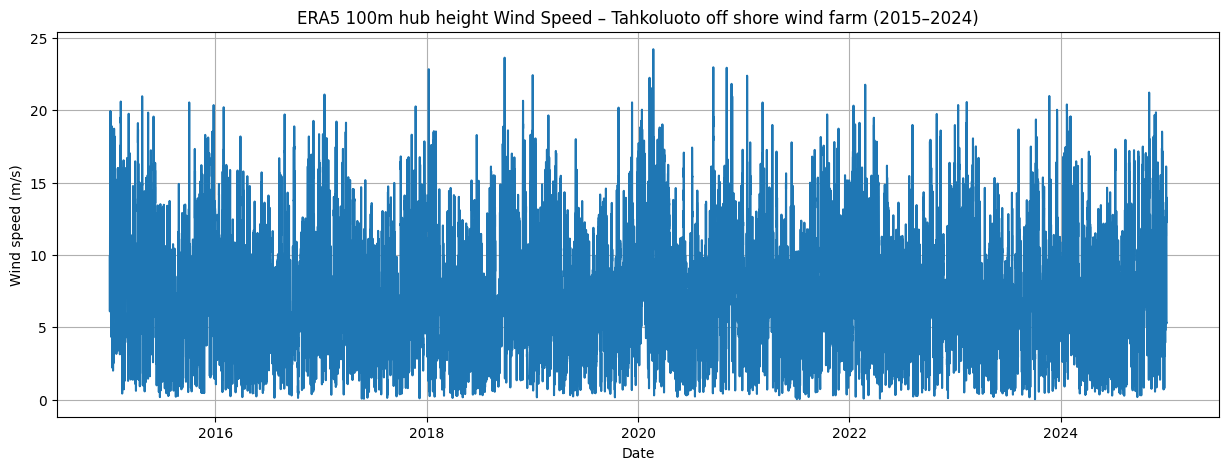

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(df["timestamp"], df["wind_speed"])
plt.xlabel("Date")
plt.ylabel("Wind speed (m/s)")
plt.title("ERA5 100m hub height Wind Speed – Tahkoluoto off shore wind farm (2015–2024)")
plt.grid(True)
plt.show()

In [19]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_year"] = df["timestamp"].dt.dayofyear

# Cyclical time features
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

In [20]:
# Previous wind speeds
for lag in [1, 3, 6, 12, 24, 48]:
    df[f"lag_{lag}"] = df["wind_speed"].shift(lag)

# Rolling averages using past observations
df["rolling_mean_6h"] = df["wind_speed"].shift(1).rolling(6).mean()
df["rolling_mean_24h"] = df["wind_speed"].shift(1).rolling(24).mean()

# Target: wind speed 24 hours into the future
df["target"] = df["wind_speed"].shift(-24)

df = df.dropna().reset_index(drop=True)

print(df.shape)
print(df.head())

(87600, 19)
            timestamp       u100       v100  wind_speed  hour  day_of_year  \
0 2015-01-03 00:00:00  18.664490  -2.528381   18.834965     0            3   
1 2015-01-03 01:00:00  16.149414  -6.294281   17.332674     1            3   
2 2015-01-03 02:00:00  13.218597  -9.674988   16.380987     2            3   
3 2015-01-03 03:00:00  13.369171 -10.070709   16.737799     3            3   
4 2015-01-03 04:00:00  13.564117 -11.190338   17.584339     4            3   

   hour_sin  hour_cos   day_sin   day_cos      lag_1      lag_3      lag_6  \
0  0.000000  1.000000  0.051584  0.998669  19.154316  19.382187  19.052309   
1  0.258819  0.965926  0.051584  0.998669  18.834965  19.198462  18.189701   
2  0.500000  0.866025  0.051584  0.998669  17.332674  19.154316  19.013990   
3  0.707107  0.707107  0.051584  0.998669  16.380987  18.834965  19.382187   
4  0.866025  0.500000  0.051584  0.998669  16.737799  17.332674  19.198462   

      lag_12     lag_24    lag_48  rolling_mean_6h

In [21]:
print("Current wind speed:")
print(df["wind_speed"].head())

print("\nWind speed 24 hours later:")
print(df["target"].head())

Current wind speed:
0    18.834965
1    17.332674
2    16.380987
3    16.737799
4    17.584339
Name: wind_speed, dtype: float32

Wind speed 24 hours later:
0    16.658901
1    16.133219
2    15.833825
3    15.683434
4    15.321840
Name: target, dtype: float32


In [22]:
# Training and validation/test boundaries
train = df[df["timestamp"] < "2022-01-01"]

validation = df[
    (df["timestamp"] >= "2022-01-01") &
    (df["timestamp"] < "2023-01-01")
]

test = df[df["timestamp"] >= "2023-01-01"]

print("Training:", train.shape)
print("Validation:", validation.shape)
print("Testing:", test.shape)

Training: (61320, 19)
Validation: (8760, 19)
Testing: (17520, 19)


In [23]:
features = [
    "u100",
    "v100",
    "wind_speed",
    "lag_1",
    "lag_3",
    "lag_6",
    "lag_12",
    "lag_24",
    "lag_48",
    "rolling_mean_6h",
    "rolling_mean_24h",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

X_train = train[features]
y_train = train["target"]

X_val = validation[features]
y_val = validation["target"]

X_test = test[features]
y_test = test["target"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (61320, 15)
X_val: (8760, 15)
X_test: (17520, 15)


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_predictions = X_test["wind_speed"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("Persistence MAE:", baseline_mae)
print("Persistence RMSE:", baseline_rmse)

Persistence MAE: 3.3193421363830566
Persistence RMSE: 4.292908547476532


In [25]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Training completed!")

Training completed!


In [26]:
predictions = model.predict(X_test)

model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("XGBoost MAE:", model_mae)
print("XGBoost RMSE:", model_rmse)

print("\nPersistence MAE:", baseline_mae)
print("Persistence RMSE:", baseline_rmse)

XGBoost MAE: 2.7581799030303955
XGBoost RMSE: 3.444457486514213

Persistence MAE: 3.3193421363830566
Persistence RMSE: 4.292908547476532


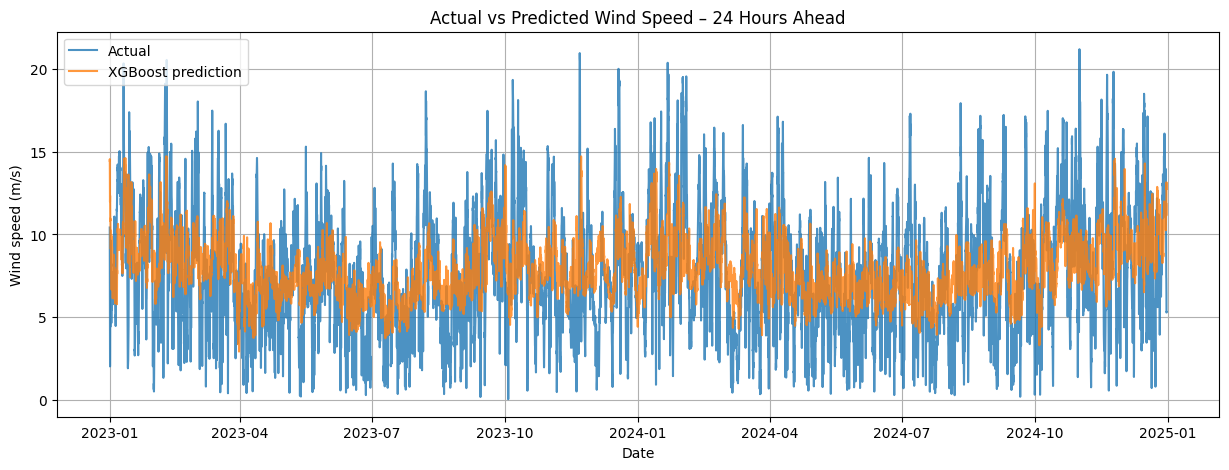

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    test["timestamp"],
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    test["timestamp"],
    predictions,
    label="XGBoost prediction",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Wind speed (m/s)")
plt.title("Actual vs Predicted Wind Speed – 24 Hours Ahead")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
threshold = 15.0

actual_high_wind = y_test >= threshold
predicted_high_wind = predictions >= threshold

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(actual_high_wind, predicted_high_wind))

print(
    classification_report(
        actual_high_wind,
        predicted_high_wind,
        zero_division=0
    )
)

[[17508     0]
 [   12     0]]
              precision    recall  f1-score   support

       False       1.00      1.00      1.00     17508
        True       0.00      0.00      0.00        12

    accuracy                           1.00     17520
   macro avg       0.50      0.50      0.50     17520
weighted avg       1.00      1.00      1.00     17520



In [ ]:
results = pd.DataFrame({
    "timestamp": test["timestamp"].values,
    "actual": y_test.values,
    "predicted": predictions
})

high_wind = results[results["actual"] >= 20]

print("Maximum actual wind speed:", results["actual"].max())
print("Maximum predicted wind speed:", results["predicted"].max())

print("\nHigh-wind observations:")
print(high_wind.head(10))

print("\nPrediction statistics for actual high-wind events:")
print(high_wind["predicted"].describe())

In [ ]:
plt.figure(figsize=(15, 5))

plt.scatter(
    results["actual"],
    results["predicted"],
    alpha=0.25
)

plt.axvline(20, linestyle="--", label="Actual threshold")
plt.axhline(20, linestyle="--", label="Prediction threshold")

plt.xlabel("Actual wind speed (m/s)")
plt.ylabel("Predicted wind speed (m/s)")
plt.title("Actual vs Predicted Wind Speed")
plt.legend()
plt.grid(True)
plt.show()